# Afiliados a la Seguridad Social por cada pensión contributiva

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "afiliados-por-pensionista"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Afiliados a la Seguridad Social por cada pensión contributiva"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "solo_espana"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "afiliados por pensión contributiva"
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Cuántos afiliados en alta laboral tiene la Seguridad Social por cada pensión contributiva que paga: el número medio de afiliados del año (todos los regímenes) entre el número medio de pensiones contributivas en vigor del sistema de la Seguridad Social.

**Por qué solo España.** Es una relación propia de un sistema de reparto con su definición de afiliado y de pensión contributiva; no hay un indicador internacional comparable. La relación demográfica equivalente, que sí se compara con otros países, está en `tasa-dependencia-mayores`.

**Cómo se lee.** Un valor de 2 significa que hay dos afiliados por cada pensión. Como el sistema es de reparto, las cotizaciones de quienes trabajan pagan, junto con las transferencias del Estado, las pensiones de cada momento.

**Limitaciones.**
- **Cuenta afiliaciones y pensiones, no personas.** Una persona puede estar afiliada en más de un régimen (pluriempleo o pluriactividad) y cobrar más de una pensión (por ejemplo, jubilación y viudedad): el cociente no es el número de trabajadores por pensionista.
- No incluye las pensiones de clases pasivas de los funcionarios, que paga el Estado, ni las no contributivas.
- Los afiliados no son todos cotizantes a tiempo completo: incluye contratos a tiempo parcial y afiliados con bases de cotización muy distintas, así que no dice cuánto se ingresa por cada pensión.
- **No hay un valor de referencia oficial.** Para que las cotizaciones paguen las pensiones, el número de afiliados por pensión tendría que ser al menos la pensión media dividida entre lo que cotiza de media cada afiliado para pensiones; ese número depende de la pensión media, de la base media de cotización y del tipo de cotización, y las cotizaciones pagan también otras prestaciones (como las bajas por enfermedad). Por eso un cociente superior a 2 puede darse con déficit, y el saldo de las cuentas está en `saldo-seguridad-social` y `saldo-seguridad-social-sin-transferencias`.
- **Serie corta.** El Ministerio de Inclusión publica en línea la afiliación media desde 2001, y la media anual de las pensiones en vigor solo está en el Boletín de Estadísticas Laborales del Ministerio de Trabajo desde 2016; los años anteriores están en anuarios que no se publican en un formato descargable.

## 2. Descarga

- **Afiliados:** Ministerio de Inclusión, Seguridad Social y Migraciones, serie de afiliación media por regímenes (total del sistema), mensual desde enero de 2001 (`lib/inclusion.py`).
- **Pensiones:** Ministerio de Trabajo y Economía Social, Boletín de Estadísticas Laborales, tabla PEN-1: pensiones contributivas del sistema de la Seguridad Social en vigor, total, media anual de los datos del primer día de cada mes (`lib/bel.py`). Son los datos del Ministerio de Inclusión.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import bel, inclusion
from lib.tipos import FuenteMeta

afil, fuentes_afil = inclusion.get_afiliacion(desde=DESDE)
pens, fuentes_pens = bel.get_pensiones(desde=DESDE)
print("Afiliados:", afil["periodo"].min(), "-", afil["periodo"].max(), "· pensiones:", pens["periodo"].min(), "-", pens["periodo"].max())

Afiliados: 2001 - 2025 · pensiones: 2016 - 2025


## 3. Transformación

Afiliados medios del año (media de las doce medias mensuales) entre las pensiones contributivas en vigor medias del año, solo en los años con los dos datos.

In [ ]:
a = afil.set_index("periodo")["valor"]
p = pens.set_index("periodo")["valor"]
ratio = (a / p).dropna()
df = pd.DataFrame({"serie": "espana", "periodo": ratio.index, "valor": ratio.values})
assert df["valor"].between(1, 4).all(), "cociente fuera de rango: ¿unidades?"
HOY = fuentes_afil[0].fecha_consulta
fuentes = [FuenteMeta(
    "espana", inclusion.ORGANISMO,
    "Afiliación media por regímenes (total del sistema) entre pensiones contributivas en vigor (BEL, PEN-1, Ministerio de Trabajo)",
    inclusion.PAGINA_AFILIACION, HOY,
)]
display(pd.DataFrame({"afiliados": a, "pensiones": p, "afiliados por pensión": a / p}).dropna().round(3))

,afiliados,pensiones,afiliados por pensión
periodo,,,
2016,1.759698e+07,9409170.0,1.870
2017,1.822308e+07,9514800.0,1.915
2018,1.878808e+07,9622520.0,1.953
2019,1.927782e+07,9740080.0,1.979
2020,1.888131e+07,9782340.0,1.930
2021,1.935731e+07,9854160.0,1.964
2022,2.010767e+07,9943040.0,2.022
2023,2.064260e+07,10051740.0,2.054
2024,2.114791e+07,10188820.0,2.076


### Notas

In [ ]:
NOTAS = [
    "Afiliados medios en alta laboral a la Seguridad Social (todos los regímenes), media anual de las medias "
    "mensuales (Ministerio de Inclusión, Seguridad Social y Migraciones), entre las pensiones contributivas en vigor "
    "del sistema de la Seguridad Social, media anual de los datos del primer día de cada mes (Boletín de Estadísticas "
    "Laborales del Ministerio de Trabajo, tabla PEN-1, con datos del Ministerio de Inclusión).",
    f"La serie empieza en {int(ratio.index.min())} porque la media anual de las pensiones en vigor solo se publica en "
    f"un formato descargable desde ese año; la afiliación media mensual está desde {int(a.index.min())}.",
    "Cuenta afiliaciones y pensiones, no personas: una persona puede estar afiliada en más de un régimen y cobrar más "
    "de una pensión. No incluye las pensiones de clases pasivas de los funcionarios ni las no contributivas.",
    "Solo España: es una relación propia de un sistema de reparto, sin indicador internacional comparable.",
]
for n in NOTAS:
    print("-", n)

- Afiliados medios en alta laboral a la Seguridad Social (todos los regímenes), media anual de las medias mensuales (Ministerio de Inclusión, Seguridad Social y Migraciones), entre las pensiones contributivas en vigor del sistema de la Seguridad Social, media anual de los datos del primer día de cada mes (Boletín de Estadísticas Laborales del Ministerio de Trabajo, tabla PEN-1, con datos del Ministerio de Inclusión).
- La serie empieza en 2016 porque la media anual de las pensiones en vigor solo se publica en un formato descargable desde ese año; la afiliación media mensual está desde 2001.
- Cuenta afiliaciones y pensiones, no personas: una persona puede estar afiliada en más de un régimen y cobrar más de una pensión. No incluye las pensiones de clases pasivas de los funcionarios ni las no contributivas.
- Solo España: es una relación propia de un sistema de reparto, sin indicador internacional comparable.


## 4. Visualización

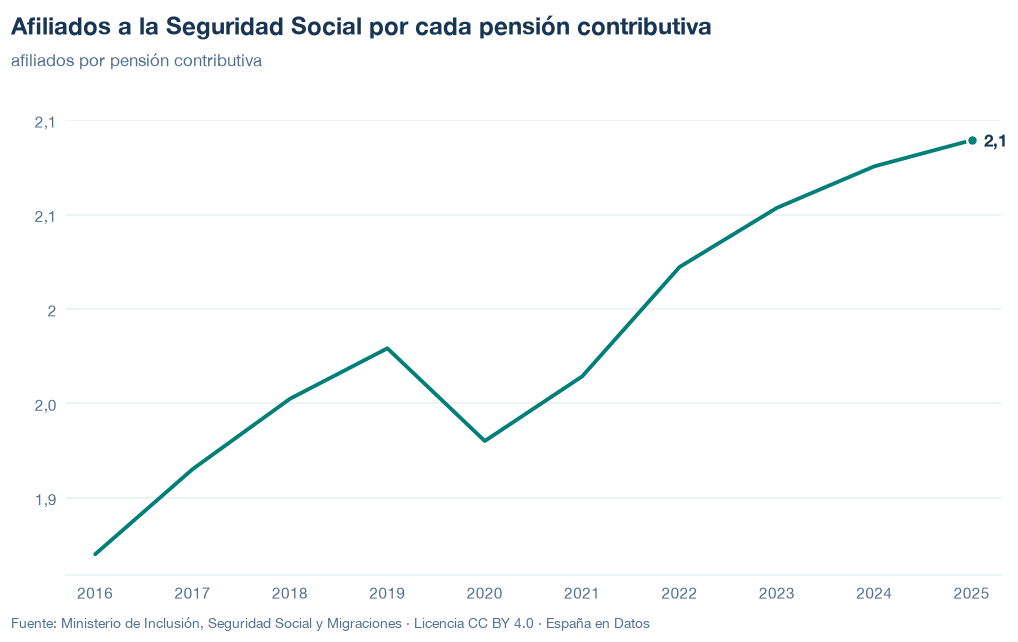

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/afiliados-por-pensionista.json y data/afiliados-por-pensionista.csv


## 6. Fuentes, notas y licencia

- Ministerio de Inclusión, Seguridad Social y Migraciones: serie de afiliación media por regímenes (total del sistema).
- Ministerio de Trabajo y Economía Social, Boletín de Estadísticas Laborales, PEN-1 (pensiones contributivas en vigor).

La fecha de consulta está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.